# Forecasting models

**A forecaster is worth trusting only if it beats a simple baseline, and the baseline to beat depends on the kind of series.**

This chapter builds `timegym.models`: four one-line baselines (last value, historical mean, seasonal persistence and drift), a fitted AR(1) that also says how uncertain it is, and an adapter that turns any scikit-learn regressor into a multi-step forecaster in three ways, called reductions.

Below, every model forecasts five kinds of series and is scored against the answer key. Each baseline wins on the kind of series it was made for, and none wins on two. Then one Ridge regression becomes a 36-step forecaster three ways, and we look inside to see what each reduction built.

**Development notebook.** The collapsed cells are the source of `timegym/models.py`; expand them to edit, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp models

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)


def plot_forecast(ax, case, forecast, title, show_last=48):
    # Gray dots for the data, a thin line for the answer key, blue crosses for the forecast.
    past = case.task.context.iloc[-show_last:, 0]
    ax.scatter(past.index, past, s=10, color='0.65', label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=16, color='0.45',
               label='What actually happened')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.5', lw=0.9, label='Answer key')
    ax.scatter(forecast.index, forecast.point[:, 0], marker='x', s=24, linewidths=1.1,
               color='#0000CC', label='Forecast', zorder=4)
    ax.axvline(forecast.index[0] - 0.5, color='#0000CC', ls='--', lw=0.9)
    ax.set(title=title, xlabel='Time step')


def error_against_answer_key(forecast, case):
    # Mean squared distance from the forecast to the answer key, over every step.
    return float(((forecast.point - case.reference.mean) ** 2).mean())

## Build the models

Five pieces: a guard on the dates to forecast, the baselines, the fitted AR(1), the scikit-learn adapter, and two helpers the pipeline uses.

### Imports, and a model that can rebuild itself

Every built-in model reports its settings (`params()`) and can rebuild an unfitted copy from them (`clone_unfitted()`). That is how TimeGym fits a fresh model for every case.

In [3]:
#| export models
from __future__ import annotations
from collections.abc import Sequence
from copy import deepcopy
from timegym._internal import positive_int, nonnegative_int, _real_array

import numpy as np
import pandas as pd
from timegym.contracts import DEFAULT_LEVELS, Forecast


class _ConfiguredForecaster:
    def clone_unfitted(self):
        return type(self)(**self.params())

### The dates to forecast must continue the history

A model that counts steps needs to know which step each requested date is. This guard accepts only dates that continue the history's regular grid without a gap, so a request that skips a step raises an error instead of quietly returning values for the wrong steps.

In [4]:
#| export models
def _require_regular_future(context_index, future_index):
    """Step-based models require the next H observations on a regular grid."""
    if not isinstance(future_index, pd.Index) or len(future_index) == 0:
        raise ValueError("future_index must be a nonempty pandas Index")
    # One observation cannot establish spacing, regardless of index type.
    if len(context_index) == 1:
        if (not future_index.is_unique or not future_index.is_monotonic_increasing
                or not future_index[0] > context_index[-1]):
            raise ValueError("future_index must be increasing and follow context")
        return
    if isinstance(context_index, (pd.DatetimeIndex, pd.TimedeltaIndex, pd.PeriodIndex)):
        frequency = context_index.freq
        if frequency is None and len(context_index) >= 3:
            frequency = pd.infer_freq(context_index)
        if frequency is None and len(context_index) == 2:
            frequency = context_index[1] - context_index[0]
        if frequency is None:
            raise ValueError("Step-based models require a regular context index with a known frequency")
        constructor = (pd.date_range if isinstance(context_index, pd.DatetimeIndex) else
                       pd.timedelta_range if isinstance(context_index, pd.TimedeltaIndex) else pd.period_range)
        expected_context = constructor(start=context_index[0], periods=len(context_index), freq=frequency)
        expected_future = constructor(start=context_index[-1], periods=len(future_index) + 1, freq=frequency)[1:]
        matches_context = context_index.equals(expected_context)
        matches_future = future_index.equals(expected_future)
    elif pd.api.types.is_numeric_dtype(context_index.dtype):
        values = context_index.to_numpy()
        step = context_index.step if isinstance(context_index, pd.RangeIndex) else (values[1] - values[0] if len(values) >= 2 else None)
        if step is None or step <= 0:
            raise ValueError("Step-based models require a regular context index with a known positive step")
        expected = values[-1] + step * np.arange(1, len(future_index) + 1)
        if pd.api.types.is_float_dtype(context_index.dtype):
            matches_context = bool(np.allclose(np.diff(values), step, rtol=1e-10, atol=0))
            roundoff = 4 * np.finfo(float).eps * max(1, np.max(np.abs(expected)))
            matches_future = (pd.api.types.is_numeric_dtype(future_index.dtype)
                              and np.allclose(future_index.to_numpy(), expected, rtol=0, atol=roundoff))
        else:
            matches_context = bool(np.all(np.diff(values) == step))
            matches_future = (pd.api.types.is_numeric_dtype(future_index.dtype)
                              and np.array_equal(future_index.to_numpy(), expected))
    else:
        raise ValueError("Step-based models require regular numeric, datetime, timedelta, or period indexes")
    if not matches_context:
        raise ValueError("Step-based models require a regular context index")
    if not matches_future:
        raise ValueError("Step-based models require consecutive future labels immediately after context")

### Four baselines in one class (`NaiveForecaster`)

Each strategy is one bet about the future:

- `last`: every future value equals the last one seen.
- `mean`: every future value equals the average of the whole history.
- `seasonal`: the last `period` values repeat.
- `drift`: the straight line from the first value to the last one carries on.

In [5]:
#| export models
class NaiveForecaster(_ConfiguredForecaster):
    """Last value, historical mean, seasonal persistence or endpoint drift.

    A single observation permits any increasing future index after context;
    its spacing cannot be verified. Longer contexts require a regular grid.
    """

    def __init__(self, strategy="last", period=1):
        strategies = ("last", "mean", "seasonal", "drift")
        if strategy not in strategies:
            raise ValueError(f"Unknown naive strategy {strategy!r}; choose from {strategies}")
        period = positive_int(period, 'period')
        self.strategy, self.period = strategy, period

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(strategy=self.strategy, period=self.period)

    def fit(self, context):
        """Keep a copy of the context; raise when it is too short for the strategy."""
        self.context_ = context.copy(deep=True)
        minimum = self.period if self.strategy == "seasonal" else (2 if self.strategy == "drift" else 1)
        if len(context) < minimum:
            raise ValueError("Insufficient context")
        return self

    def predict(self, future_index):
        """Return a point forecast for labels that continue the context's grid."""
        _require_regular_future(self.context_.index, future_index)
        y = self.context_.to_numpy(dtype=float)
        h = len(future_index)
        if self.strategy == "mean":
            point = np.tile(y.mean(axis=0), (h, 1))
        elif self.strategy == "seasonal":
            point = y[-self.period:][np.arange(h) % self.period]
        elif self.strategy == "drift":
            point = y[-1] + np.arange(1, h + 1)[:, None] * (y[-1] - y[0]) / (len(y) - 1)
        else:
            point = np.tile(y[-1], (h, 1))
        return Forecast(index=future_index.copy(), point=point,
                        target_names=tuple(self.context_.columns))

### The last value by name (`LastValueForecaster`)

`LastValueForecaster()` makes the same forecasts as `NaiveForecaster("last")` and has nothing to set, so reports and scorecards call it by name: a scorecard reads *LastValueForecaster: 51/100*. It is the baseline the README and the quick start score.

In [6]:
#| export models
class LastValueForecaster(NaiveForecaster):
    """Repeat each series' last observed value at every future step.

    The same forecasts as ``NaiveForecaster("last")``, with no settings, so
    reports and scorecards name it ``LastValueForecaster``.
    """

    def __init__(self):
        super().__init__(strategy="last", period=1)

    def params(self) -> dict:
        """No settings: ``clone_unfitted`` rebuilds a plain ``LastValueForecaster()``."""
        return {}

### A fitted AR(1) that says how uncertain it is (`GaussianAR1Forecaster`)

This model bets on mean reversion (AR(1)): shocks fade and the series drifts back toward a long-run level. It fits that recipe to the history by least squares and simulates 256 future paths from it. The point forecast is the exact mean of the fitted model; quantiles and samples come from the paths. With several targets, each gets its own equation and their shocks may be correlated.

In [7]:
#| export models
class GaussianAR1Forecaster(_ConfiguredForecaster):
    """Per-target OLS AR(1) with intercept and paired Gaussian innovations.

    Residual innovation covariance is pooled across targets with n-3 degrees
    of freedom for n context observations. The point is the exact iterated
    conditional mean under fitted parameters. Joint samples (256 by default)
    and marginal quantiles at ``levels`` come from a seeded Monte Carlo
    generator. This baseline omits parameter uncertainty and is not a reference.
    """

    def __init__(self, n_samples=256, seed=0, levels=DEFAULT_LEVELS):
        n_samples = positive_int(n_samples, 'n_samples')
        if n_samples < 2:
            raise ValueError('n_samples must be an integer >= 2')
        seed = None if seed is None else nonnegative_int(seed, "seed")
        probabilities = _real_array(levels, "levels")
        if probabilities.ndim != 1 or not probabilities.size:
            raise ValueError("levels must be a nonempty one-dimensional sequence")
        if (not np.isfinite(probabilities).all()
                or np.any((probabilities <= 0) | (probabilities >= 1))):
            raise ValueError("levels must be finite and strictly between zero and one")
        if np.any(np.diff(probabilities) <= 0):
            raise ValueError("levels must be unique and increasing")
        self.n_samples, self.seed = n_samples, seed
        self.levels = tuple(float(value) for value in probabilities)

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(n_samples=self.n_samples, seed=self.seed, levels=self.levels)

    def fit(self, context):
        """Fit each target's intercept and AR(1) coefficient, and the shared innovation covariance.

        Needs at least five context rows.
        """
        y = context.to_numpy(dtype=float)
        if len(y) < 5:
            raise ValueError("AR(1) requires at least five context observations")
        self.names_ = tuple(context.columns)
        self.index_ = context.index.copy()
        self.last_ = y[-1].copy()
        coefs = [np.linalg.lstsq(np.column_stack([np.ones(len(y)-1), y[:-1, d]]),
                                y[1:, d], rcond=None)[0] for d in range(y.shape[1])]
        self.intercept_, self.phi_ = np.asarray(coefs).T
        residuals = y[1:] - self.intercept_ - y[:-1] * self.phi_
        self.cov_ = residuals.T @ residuals / (len(residuals) - 2)
        return self

    def predict(self, future_index):
        """Return the iterated mean, seeded joint samples and their marginal quantiles."""
        _require_regular_future(self.index_, future_index)
        h, d = len(future_index), len(self.names_)
        point, samples = np.empty((h, d)), np.empty((self.n_samples, h, d))
        rng = np.random.default_rng(self.seed)
        last_mean, last_samples = self.last_.copy(), np.tile(self.last_, (self.n_samples, 1))
        for i in range(h):
            last_mean = self.intercept_ + self.phi_ * last_mean
            last_samples = self.intercept_ + self.phi_ * last_samples + rng.multivariate_normal(
                np.zeros(d), self.cov_, self.n_samples)
            point[i], samples[:, i] = last_mean, last_samples
        levels = self.levels
        quantiles = np.moveaxis(np.quantile(samples, levels, axis=0), 0, -1)
        return Forecast(index=future_index.copy(), point=point, quantiles=quantiles,
                        levels=levels, samples=samples, target_names=self.names_)

### Lag windows: a series cut into regression rows

A regressor learns from rows of inputs and labels. A lag window makes one such row from the history: `window_length` consecutive values as inputs, and the value or values that came next as labels. Every reduction trains on these windows, and no label lies beyond the end of the history.

In [8]:
#| export models
REDUCTIONS = ("recursive", "direct", "multioutput")


def _lag_windows(values, window_length, steps):
    """Pair each flattened lag window, oldest row first, with its next ``steps`` rows.

    Only windows whose labels are rows of ``values`` are returned, so no
    training label lies beyond the last context observation.
    """
    count = len(values) - window_length - steps + 1
    windows = np.asarray([values[i:i + window_length].ravel() for i in range(count)])
    labels = np.asarray([values[i + window_length:i + window_length + steps] for i in range(count)])
    return windows, labels


def _native_multioutput(estimator):
    """Read sklearn's multioutput tag; releases before 1.6 expose it through _get_tags."""
    try:
        from sklearn.utils import get_tags
    except ImportError:
        return bool(estimator._get_tags().get("multioutput", False))
    return bool(get_tags(estimator).target_tags.multi_output)

### Any scikit-learn regressor as a forecaster (`SklearnForecaster`)

Pass the steps of a scikit-learn pipeline, ending with a regressor. Every fit starts from fresh copies of the steps, so a scaler learns only from the training windows. The reduction decides how a regressor reaches many steps ahead:

- `recursive`: predict one step, append the prediction to the window as if it had happened, and repeat.
- `direct`: fit a separate regressor for each step ahead, each predicting from the last observed window.
- `multioutput`: fit one regressor that predicts every step at once. A regressor that can only predict one value is wrapped in scikit-learn's `MultiOutputRegressor`, which makes it the same as direct.

Direct and multioutput need `horizon`, the longest forecast they will be asked for, to build their labels.

In [9]:
#| export models
class SklearnForecaster(_ConfiguredForecaster):
    """Reduce an sklearn regression pipeline to multi-step forecasts from lag windows.

    Every reduction trains on the same flattened lag windows of the context,
    oldest row first, and fits transformers only on those training rows.
    ``recursive`` fits one-step regressors and appends each prediction to the
    window. ``direct`` fits one regressor per horizon step and target, always
    from the last observed window. ``multioutput`` fits one regressor per
    target for the whole horizon vector, wrapping the final step in
    MultiOutputRegressor when it lacks native multioutput support.
    ``horizon`` is the longest forecast returned; direct and multioutput
    need it to build their labels.
    """

    def __init__(self, steps, window_length=12, reduction="recursive", horizon=None):
        window_length = positive_int(window_length, 'window_length')
        if not isinstance(steps, Sequence) or isinstance(steps, (str, bytes)) or not steps:
            raise ValueError("steps must be a nonempty sequence ending in an sklearn regressor")
        if not is_sklearn_regressor(steps[-1]):
            raise ValueError(f"Final step {steps[-1]!r} must be an sklearn regressor")
        if reduction not in REDUCTIONS:
            raise ValueError(f"Unknown reduction {reduction!r}; choose from {REDUCTIONS}")
        if horizon is not None:
            horizon = positive_int(horizon, 'horizon')
        elif reduction != "recursive":
            raise ValueError(f"The {reduction} reduction requires a positive integer horizon")
        self.steps, self.window_length = list(steps), window_length
        self.reduction, self.horizon = reduction, horizon

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return dict(steps=self.steps, window_length=self.window_length,
                    reduction=self.reduction, horizon=self.horizon)

    def _estimator(self, multioutput=False):
        from sklearn.base import clone
        from sklearn.multioutput import MultiOutputRegressor
        from sklearn.pipeline import Pipeline as SkPipeline

        steps = [clone(step) for step in self.steps]
        if multioutput and not _native_multioutput(steps[-1]):
            steps[-1] = MultiOutputRegressor(steps[-1])
        return SkPipeline([(f"step_{i}", step) for i, step in enumerate(steps)])

    def fit(self, context):
        """Fit fresh copies of the steps on lag windows of the context.

        ``recursive`` needs ``window_length + 1`` context rows; ``direct`` and
        ``multioutput`` need ``window_length + horizon``.
        """
        y = context.to_numpy(dtype=float)
        steps = 1 if self.reduction == "recursive" else self.horizon
        if len(y) < self.window_length + steps:
            raise ValueError(f"The {self.reduction} reduction needs at least window_length + {steps} = "
                             f"{self.window_length + steps} context rows")
        self.names_, self.history_ = tuple(context.columns), y.copy()
        self.index_ = context.index.copy()
        windows, labels = _lag_windows(y, self.window_length, steps)
        targets = range(y.shape[1])
        if self.reduction == "direct":
            self.models_ = [[self._estimator().fit(windows, labels[:, step, d]) for step in range(steps)]
                            for d in targets]
        elif self.reduction == "multioutput" and steps > 1:
            self.models_ = [self._estimator(multioutput=True).fit(windows, labels[:, :, d]) for d in targets]
        else:
            self.models_ = [self._estimator().fit(windows, labels[:, 0, d]) for d in targets]
        return self

    def predict(self, future_index):
        """Return a point forecast from the last context window.

        The labels must continue the context's grid; with a ``horizon``, there
        can be at most that many.
        """
        _require_regular_future(self.index_, future_index)
        h = len(future_index)
        if self.horizon is not None and h > self.horizon:
            raise ValueError(f"future_index has {h} labels; this model forecasts at most {self.horizon}")
        window = self.history_[-self.window_length:].reshape(1, -1)
        if self.reduction == "direct":
            predictions = [[models[step].predict(window).item() for models in self.models_] for step in range(h)]
        elif self.reduction == "multioutput":
            predictions = np.column_stack([model.predict(window).reshape(-1)[:h] for model in self.models_])
        else:
            history, predictions = list(self.history_.copy()), []
            for _ in future_index:
                x = np.asarray(history[-self.window_length:]).reshape(1, -1)
                step = np.asarray([model.predict(x).item() for model in self.models_])
                predictions.append(step)
                history.append(step)
        return Forecast(index=future_index.copy(), point=np.asarray(predictions), target_names=self.names_)

### A fresh model for every case (`fresh_model`)

TimeGym never fits the object you pass in. It fits a copy: built-in models rebuild from their settings, scikit-learn estimators are cloned, and anything else is deep-copied, so pass your own models unfitted.

In [10]:
#| export models
def fresh_model(model):
    """Return a fresh copy of a model for one case, never the caller's object.

    Models with ``clone_unfitted()`` rebuild themselves from configuration;
    sklearn estimators are cloned. Any other instance is deep-copied as
    supplied, so pass it unfitted: TimeGym never fits the original object and
    calls ``fit`` on every copy, so state does not leak between cases unless
    ``fit`` itself reuses state it was given.
    """
    if callable(getattr(model, "clone_unfitted", None)):
        cloned = model.clone_unfitted()
        if cloned is model:
            raise ValueError("clone_unfitted() must return a new model instance")
        return cloned
    if hasattr(model, "get_params"):
        from sklearn.base import clone

        return clone(model)
    return deepcopy(model)

### Is it a scikit-learn regressor? (`is_sklearn_regressor`)

scikit-learn is imported only when a model looks like one of its estimators, so the native models work without it.

In [11]:
#| export models
def is_sklearn_regressor(model):
    """Read estimator tags lazily, importing sklearn only when it is needed."""
    if not hasattr(model, "get_params"):
        return False
    from sklearn.base import is_regressor

    return bool(is_regressor(model))

## Four bets about the future

Each baseline is the right forecast for one kind of series. We test them on five kinds, each with 120 steps of history and 24 to forecast. Because we generate the data, every case comes with the **answer key**: the best forecast a forecaster that knows the true recipe could make from the same history.

In [12]:
from timegym import Scenario

SERIES = {
    'Noise around a constant level': Scenario('white_noise', context_length=120, horizon=24,
                                              parameters={'mean': 5., 'sigma': 1.}),
    'Noise around a straight line': Scenario('trend', context_length=120, horizon=24,
                                             parameters={'slope': .1, 'sigma': 1.}),
    'Noise around a repeating cycle': Scenario('seasonal', context_length=120, horizon=24,
                                               parameters={'amplitude': 3., 'period': 12., 'sigma': 1.}),
    'Mean reversion (AR(1))': Scenario('ar1', context_length=120, horizon=24,
                                       parameters={'phi': .85, 'sigma': 1.}),
    'Random walk': Scenario('random_walk', context_length=120, horizon=24),
}

First, each of the four baselines on the kind of series its bet matches (the first draw of each):

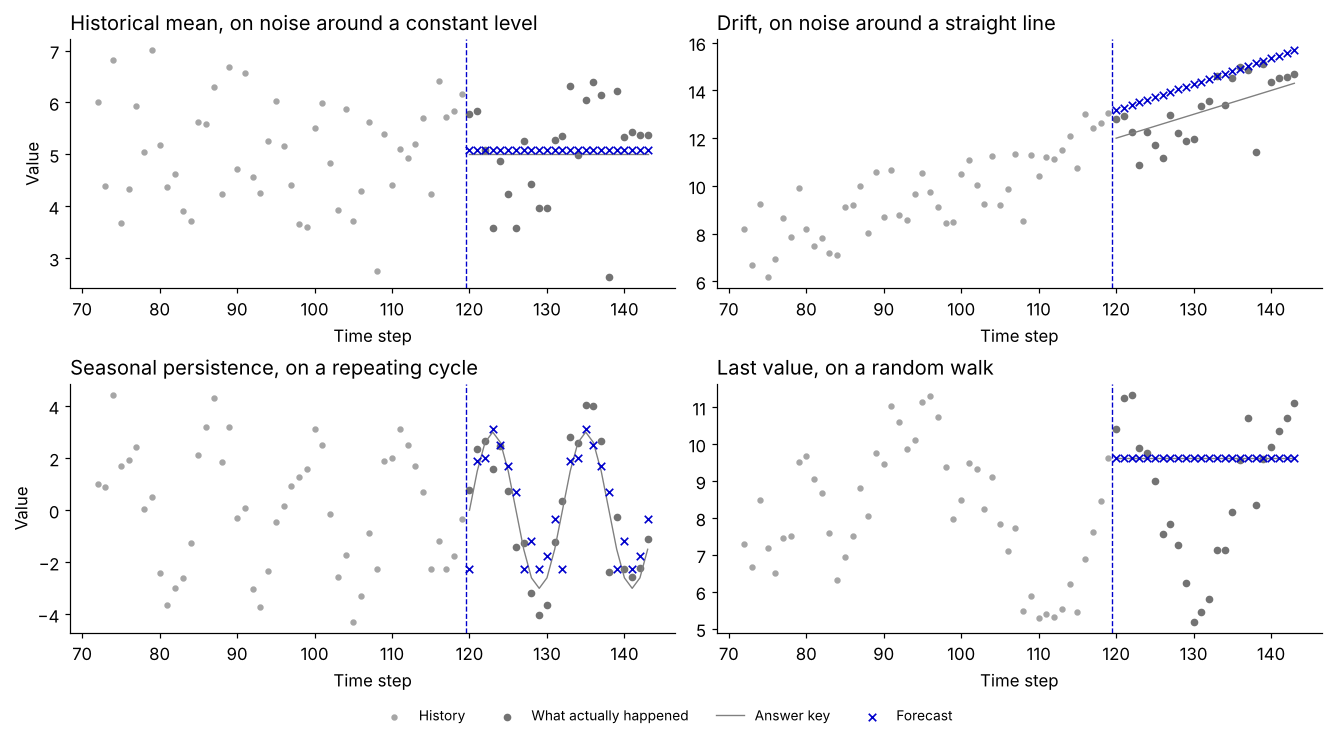

In [13]:
home_series = [
    ('Historical mean, on noise around a constant level', NaiveForecaster('mean'), 'Noise around a constant level'),
    ('Drift, on noise around a straight line', NaiveForecaster('drift'), 'Noise around a straight line'),
    ('Seasonal persistence, on a repeating cycle', NaiveForecaster('seasonal', period=12), 'Noise around a repeating cycle'),
    ('Last value, on a random walk', NaiveForecaster('last'), 'Random walk'),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 6.6), layout='constrained')
for ax, (title, model, kind) in zip(axes.flat, home_series):
    case = SERIES[kind].generate(seed=0)
    plot_forecast(ax, case, model.fit(case.task.context).predict(case.task.future_index), title)
for ax in axes[:, 0]:
    ax.set_ylabel('Value')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
plt.show()

Each forecast follows the answer key, and each misses it in its own way. The historical mean averages 120 values, so their noise mostly cancels and the crosses sit on the line. Seasonal persistence copies the last cycle, and that cycle's noise with it, so its crosses scatter around the curve. The drift line runs parallel to the answer key but starts from the last value, noise included, so in this draw it sits above the answer key all the way. On the random walk the crosses cover the answer key: when shocks never fade, the last value is the best forecast there is.

## Which baseline to beat

A bet that is right on one kind of series can be badly wrong on another. Here all four baselines and the fitted AR(1) forecast 20 draws of every kind of series. The table shows each model's average error against the answer key: 0 means as good as the answer key.

In [14]:
MODELS = {'Historical mean': lambda: NaiveForecaster('mean'),
          'Drift': lambda: NaiveForecaster('drift'),
          'Seasonal persistence': lambda: NaiveForecaster('seasonal', period=12),
          'Fitted AR(1)': lambda: GaussianAR1Forecaster(seed=0),
          'Last value': lambda: NaiveForecaster('last')}
rows = []
for kind, scenario in SERIES.items():
    for seed in range(20):
        case = scenario.generate(seed=seed)
        for name, make_model in MODELS.items():
            forecast = make_model().fit(case.task.context).predict(case.task.future_index)
            assert forecast.validate(case.task) == []  # right dates, target and shape
            rows.append({'kind': kind, 'model': name, 'error': error_against_answer_key(forecast, case)})
errors = (pd.DataFrame(rows).groupby(['kind', 'model'])['error'].mean().unstack()
          .reindex(index=list(SERIES), columns=list(MODELS)).rename_axis(index='Kind of series', columns=None))
errors['Baseline to beat'] = errors.idxmin(axis=1)

assert list(errors['Baseline to beat']) == list(MODELS)  # each model wins on the series its bet matches
assert errors.loc['Random walk', 'Last value'] < 1e-12   # on a random walk the last value is the answer key
errors.round(2)

,Historical mean,Drift,Seasonal persistence,Fitted AR(1),Last value,Baseline to beat
Kind of series,,,,,,
Noise around a constant level,0.01,0.78,1.10,0.01,0.60,Historical mean
Noise around a straight line,52.51,0.78,4.57,19.52,3.22,Drift
Noise around a repeating cycle,4.51,8.73,1.10,5.06,8.05,Seasonal persistence
Mean reversion (AR(1)),0.37,1.37,2.94,0.18,0.88,Fitted AR(1)
Random walk,27.71,1.40,2.80,0.92,0.00,Last value


The winners line up on the diagonal: each model is best on the kind of series it bets on, and none is best on two. Being right on one kind says little about the others. The historical mean, best on noise around a constant level, has the largest errors in the table on the straight line (52.51) and the random walk (27.71): it forecasts a series that has moved as if it had not. The fitted AR(1) is a close second on the constant level (both round to 0.01), since with nothing to revert it is nearly the mean. On a random walk (0.92) it estimates a weight a little below 1 and pulls back toward a level the walk doesn't have.

Seasonal persistence and drift remove their pattern exactly, so their errors on their own series (1.10 and 0.78) equal their errors on noise around a constant level. What remains is the noise in the few values they forecast from, which the historical mean averages away.

So if your series wanders like a random walk, the last value is the baseline to beat, and on this random walk it is the answer key itself. The [Quick start](../tutorials/01_quick_start.ipynb) scorecard tells the same story: the last value nails the random walk and fails on the trend and the cycle.

## Mean reversion: between the last value and the mean

On mean reversion no one-line bet is right. The answer key starts near the last value and decays toward the long-run level, so the last value is right only at first and the mean only later. The fitted AR(1) learns the decay from the history. Here are all three on the first draw, each with its error against the answer key. The shaded band runs from the fitted model's 10% quantile to its 90% quantile.

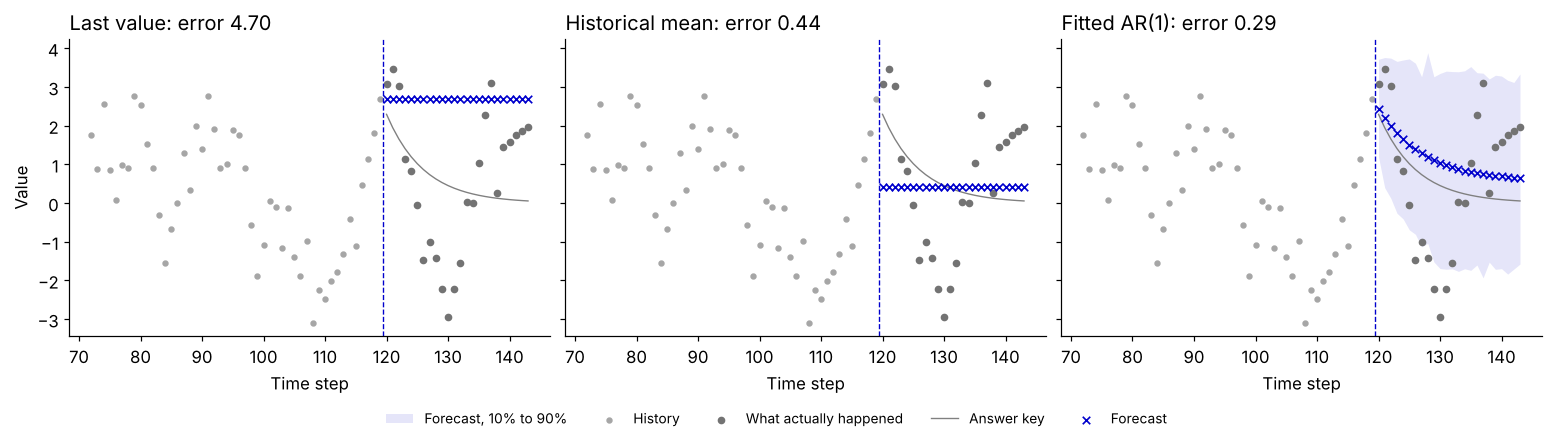

The fitted AR(1) estimates a weight of 0.87 (true 0.85) and a long-run level of 0.56 (true 0.00), and its band comes from 256 simulated paths.


In [15]:
case = SERIES['Mean reversion (AR(1))'].generate(seed=0)
contenders = {'Last value': NaiveForecaster('last'), 'Historical mean': NaiveForecaster('mean'),
              'Fitted AR(1)': GaussianAR1Forecaster(seed=0)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True, layout='constrained')
for ax, (name, model) in zip(axes, contenders.items()):
    forecast = model.fit(case.task.context).predict(case.task.future_index)
    if forecast.quantiles is not None:  # only the fitted AR(1) says how uncertain it is
        ax.fill_between(forecast.index, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                        color='#0000CC', alpha=0.1, lw=0, label='Forecast, 10% to 90%')
    plot_forecast(ax, case, forecast, f'{name}: error {error_against_answer_key(forecast, case):.2f}')
axes[0].set_ylabel('Value')
fig.legend(*axes[-1].get_legend_handles_labels(), loc='outside lower center', ncol=5, fontsize=9)
plt.show()

ar1, truth = contenders['Fitted AR(1)'], case.manifest['parameters']
print(f"The fitted AR(1) estimates a weight of {ar1.phi_[0]:.2f} (true {truth['phi']:.2f}) and a long-run level "
      f"of {ar1.intercept_[0] / (1 - ar1.phi_[0]):.2f} (true {truth['mean'][0]:.2f}), "
      f"and its band comes from {ar1.n_samples} simulated paths.")

The last value stays at about 2.7 while the answer key falls toward 0 (error 4.70). The historical mean starts far too low and is close only at the end (0.44). The fitted AR(1) falls from the last value as the answer key does (0.29), but toward 0.56 rather than 0: it has to estimate from 120 values the long-run level that the answer key knows. Its band widens over the first few steps, while shocks pile up, then stops widening as they fade. The band treats the fitted weight and level as exact, so on short histories it is a little too narrow.

## One regressor, three reductions

Now the scikit-learn adapter. A scaled Ridge regression must forecast 36 steps of noise around a repeating cycle with a 24-step period, from windows of the last 8 values. Eight values cover a third of the cycle, so the one-step model is short-sighted on purpose. All three reductions get the same regressor, the same 240 steps of history and the same 8-value windows as inputs.

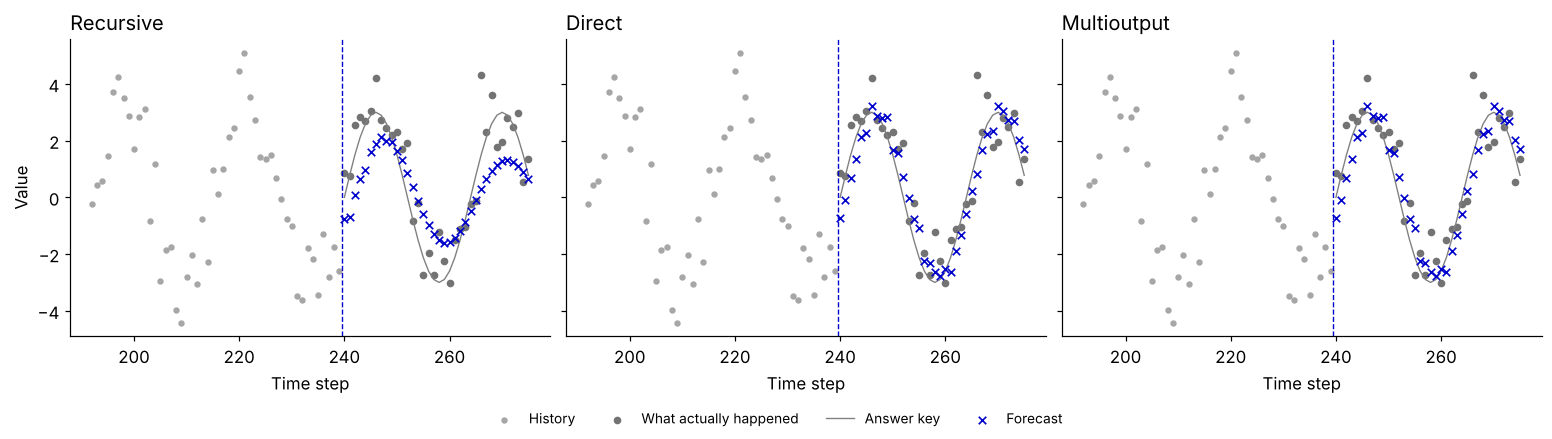

In [16]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

seasonal_case = Scenario('seasonal', context_length=240, horizon=36,
                         parameters={'amplitude': 3., 'period': 24., 'sigma': 1.}).generate(seed=4)
history, dates = seasonal_case.task.context, seasonal_case.task.future_index
fitted = {reduction: SklearnForecaster([StandardScaler(), Ridge(alpha=1.)], window_length=8,
                                       reduction=reduction, horizon=len(dates)).fit(history)
          for reduction in REDUCTIONS}
reduced = {reduction: model.predict(dates) for reduction, model in fitted.items()}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True, layout='constrained')
for ax, (reduction, forecast) in zip(axes, reduced.items()):
    plot_forecast(ax, seasonal_case, forecast, reduction.capitalize())
axes[0].set_ylabel('Value')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
plt.show()

The recursive forecast follows the cycle with too small a swing, and the swing shrinks further as its own predictions fill the window. Direct and multioutput keep the full swing, because each step ahead is learned from real windows of history, not from earlier forecasts.

What did each reduction build? The fitted models can tell us:

In [17]:
def regressors(model):
    # One target here, so models_[0] holds its regressors: a list of them for direct.
    return model.models_[0] if model.reduction == 'direct' else [model.models_[0]]


anatomy = pd.DataFrame([{
    'reduction': reduction,
    'regressors fitted': len(regressors(model)),
    'training windows': int(regressors(model)[0][0].n_samples_seen_),
    'steps each regressor predicts': np.atleast_2d(regressors(model)[0][-1].coef_).shape[0],
    'error against the answer key': error_against_answer_key(reduced[reduction], seasonal_case),
} for reduction, model in fitted.items()]).set_index('reduction')

np.testing.assert_allclose(reduced['direct'].point, reduced['multioutput'].point,
                           rtol=1e-8, atol=1e-8)  # for Ridge, multioutput is direct
assert (anatomy.loc['recursive', 'error against the answer key']
        > 2 * anatomy.loc['direct', 'error against the answer key'])  # recursive loses the swing
anatomy.round(3)

,regressors fitted,training windows,steps each regressor predicts,error against the answer key
reduction,,,,
recursive,1,232,1,1.387
direct,36,197,1,0.329
multioutput,1,197,36,0.329


Recursive fits one regressor on 232 one-step windows and uses it 36 times. Direct fits 36 regressors, one per step ahead. Multioutput fits one regressor that predicts all 36 steps at once. Direct and multioutput learn from 197 windows, not 232, because every label must fall inside the history: reaching 36 steps ahead costs 35 training windows. Even so, their error against the answer key is about a quarter of recursive's (0.329 against 1.387).

Direct and multioutput give the same forecast. Ridge fits each output by the same penalized least squares on the same inputs, so fitting the 36 together changes nothing. A model that shares what it learns across outputs, such as a random forest, separates them. [Reductions](../tutorials/05_reductions.ipynb) repeats this comparison over 40 series and shows when recursive errors compound and when they don't.

## Mistakes the models refuse

Some mistakes would not crash: they would quietly return a wrong forecast. The models raise an error instead. Three of them:

In [18]:
attempts = {
    'Forecast dates that skip the first step':
        lambda: NaiveForecaster('last').fit(history).predict(dates + 1),
    'A scikit-learn pipeline that ends in a scaler':
        lambda: SklearnForecaster([StandardScaler()]),
    '36 dates from a direct model built for 12':
        lambda: SklearnForecaster([Ridge()], reduction='direct', horizon=12).fit(history).predict(dates),
}
refusals = []
for attempt, call in attempts.items():
    try:
        call()
    except ValueError as error:
        refusals.append({'what we tried': attempt, 'what the model said': str(error)})
assert len(refusals) == len(attempts)  # every one is refused
display(pd.DataFrame(refusals))

,what we tried,what the model said
0,Forecast dates that skip the first step,Step-based models require consecutive future labels immediately after context
1,A scikit-learn pipeline that ends in a scaler,Final step StandardScaler() must be an sklearn regressor
2,36 dates from a direct model built for 12,future_index has 36 labels; this model forecasts at most 12


Each message names the problem. The first matters most: values for the wrong steps would have the right shape and look plausible.

## A fresh copy for every case

TimeGym fits a copy of your model for every case, never the object you passed in, so nothing learned on one history leaks into the next. `fresh_model` makes that copy, here from a model that has already been fitted:

In [19]:
fitted_model = NaiveForecaster('seasonal', period=12).fit(history)
fresh = fresh_model(fitted_model)
assert fresh is not fitted_model and fresh.params() == fitted_model.params()  # same settings,
assert not hasattr(fresh, 'context_')                                         # nothing learned
print(f'fresh_model returned a new {type(fresh).__name__} with the settings {fresh.params()} '
      'and no history.')

fresh_model returned a new NaiveForecaster with the settings {'strategy': 'seasonal', 'period': 12} and no history.


**Limits.** The baselines and the reductions return point forecasts only; the fitted AR(1) is the one model here that also gives quantiles and samples. Each figure shows a single draw, and the baseline table averages 20 draws of five recipes: it shows where each bet belongs, not a general ranking. Models that count steps need dates on a regular grid.

## Change one thing

- Set the cycle's `amplitude` to 1 in `SERIES`. Does seasonal persistence still beat the historical mean on its own series?
- Give the random walk a drift of 0.2 per step (`parameters={'drift': 0.2}`). Which baseline is the one to beat now?
- Give the reductions a whole cycle to look at (`window_length=24`). Does recursive still lose the swing?
- Replace Ridge with a `RandomForestRegressor`, and direct and multioutput part ways.

**Next:** [Pipeline](07_pipeline.ipynb) fits these models case by case and scores them. [Reductions](../tutorials/05_reductions.ipynb) compares the three reductions over many series.